In [1]:
import os
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from PIL import Image

In [2]:

data_dir = Path("C:\\Ha\\Data Deep\\data")
train_dir = data_dir / 'Train_Alphabet'
test_dir = data_dir / 'Test_Alphabet'



## 1. Dataset Overview

### 1.1. Classes and Image Counts


In [3]:
train_classes = []
for p in train_dir.iterdir():
    if p.is_dir():
        train_classes.append(p.name)
train_classes.sort()

test_classes = []
for p in test_dir.iterdir():
    if p.is_dir():
        test_classes.append(p.name)
test_classes.sort()

print("train classes:", train_classes)
print("test classes:", test_classes)
print("\nNumber of train classes:", len(train_classes))
print("Number of test classes:", len(test_classes))

train classes: ['A', 'B', 'Blank', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']
test classes: ['A', 'B', 'Blank', 'C', 'D', 'E', 'F', 'G', 'H', 'I', 'J', 'K', 'L', 'M', 'N', 'O', 'P', 'Q', 'R', 'S', 'T', 'U', 'V', 'W', 'X', 'Y', 'Z']

Number of train classes: 27
Number of test classes: 27


In [4]:
# Count images in train and test folders

image_extensions = [".jpg", ".jpeg", ".png", ".webp"]

train_count = 0
test_count = 0

for file in train_dir.rglob("*"):
    if file.is_file():
        if file.suffix.lower() in image_extensions:
            train_count += 1

for file in test_dir.rglob("*"):
    if file.is_file():
        if file.suffix.lower() in image_extensions:
            test_count += 1

print("Train images:", train_count)
print("Test images:", test_count)
print("Total images:", train_count + test_count)

Train images: 24300
Test images: 2700
Total images: 27000


### 1.2. Image Metadata Table

Build a table of image paths, classes, and dataset splits.


In [5]:
data = []
folders = {"train": train_dir, "test": test_dir}

for split, folder in folders.items():
    for class_folder in sorted(folder.iterdir()):
        if not class_folder.is_dir():
            continue
        for image in class_folder.iterdir():
            if not image.is_file():
                continue
            if image.suffix.lower() not in image_extensions:
                continue
            data.append({
                "Path": str(image),
                "Class": class_folder.name,
                "Split": split
            })
df = pd.DataFrame(data)
print("số dòng, cột:", df.shape)
display(df.head())

số dòng, cột: (27000, 3)


,Path,Class,Split
0,C:\Ha\Data Deep\data\Train_Alphabet\A\0042513a...,A,train
1,C:\Ha\Data Deep\data\Train_Alphabet\A\00523102...,A,train
2,C:\Ha\Data Deep\data\Train_Alphabet\A\006f6ffe...,A,train
3,C:\Ha\Data Deep\data\Train_Alphabet\A\00849d5c...,A,train
4,C:\Ha\Data Deep\data\Train_Alphabet\A\00961ff1...,A,train


The table contains 27,000 rows and three columns: Path, Class, and Split.


### 1.3. Metadata Checks

Check image counts, class counts, missing values, and duplicate paths.


In [6]:
print("Total images:", len(df))

print("\nImages in each split:")
print(df["Split"].value_counts())

print("\nNumber of classes:")
print(df.groupby("Split")["Class"].nunique())

print("\nMissing values:")
print(df.isnull().sum())

print("\nDuplicate paths:")
print(df["Path"].duplicated().sum())

Total images: 27000

Images in each split:
Split
train    24300
test      2700
Name: count, dtype: int64

Number of classes:
Split
test     27
train    27
Name: Class, dtype: int64

Missing values:
Path     0
Class    0
Split    0
dtype: int64

Duplicate paths:
0


No missing values or duplicate paths were found.


### 1.4. Class Balance


In [7]:
class_counts = pd.crosstab(df["Class"], df["Split"])
class_counts = class_counts.sort_index()
class_counts["Total"] = class_counts.sum(axis=1)
for split in ["train", "test"]:
    counts = class_counts[split]
    print(f"\ntập {split}:")
    print("min:", counts.min())
    print("max:", counts.max())
    print("mean:", round(counts.mean(), 2))
    print("std:", round(counts.std(), 2))

    missing_classes = counts[counts == 0].index.tolist()
    print("missing cl", missing_classes)


tập train:
min: 900
max: 900
mean: 900.0
std: 0.0
missing cl []

tập test:
min: 100
max: 100
mean: 100.0
std: 0.0
missing cl []


Class counts have zero standard deviation in both splits; no classes are missing.


### 1.5. Train/Test Ratios

Calculate the train/test ratio for each class.


In [8]:
class_counts["Train_Ratio"] = (class_counts["train"] / class_counts["Total"])
class_counts["Test_Ratio"] = (class_counts["test"] / class_counts["Total"])
display(class_counts[["train", "test", "Train_Ratio", "Test_Ratio"]].round(3))

Split,train,test,Train_Ratio,Test_Ratio
Class,,,,
A,900,100,0.9,0.1
B,900,100,0.9,0.1
Blank,900,100,0.9,0.1
C,900,100,0.9,0.1
D,900,100,0.9,0.1
E,900,100,0.9,0.1
F,900,100,0.9,0.1
G,900,100,0.9,0.1
H,900,100,0.9,0.1


Every class follows the predefined 90% train / 10% test split.


## 2. Image Properties


### 2.1. File Metadata

Read dimensions, color mode, format, aspect ratio, and file size.


In [9]:
image_info = []

for _, row in df.iterrows():
    path = row["Path"]
    with Image.open(path) as img:
        width = img.width
        height = img.height
        file_size = os.path.getsize(path) / 1024
        info = {}
        info["path"] = path
        info["class"] = row["Class"]
        info["split"] = row["Split"]
        info["width"] = width
        info["height"] = height
        info["mode"] = img.mode
        info["format"] = img.format
        info["aspect_ratio"] = width / height
        info["file_size_kb"] = round(file_size, 2)
        info["readable"] = True
        image_info.append(info)

df_images = pd.DataFrame(image_info)
df_images.head()

,path,class,split,width,height,mode,format,aspect_ratio,file_size_kb,readable
0,C:\Ha\Data Deep\data\Train_Alphabet\A\0042513a...,A,train,513,512,RGB,PNG,1.001953,201.78,True
1,C:\Ha\Data Deep\data\Train_Alphabet\A\00523102...,A,train,513,512,RGB,PNG,1.001953,262.67,True
2,C:\Ha\Data Deep\data\Train_Alphabet\A\006f6ffe...,A,train,513,512,RGB,PNG,1.001953,250.54,True
3,C:\Ha\Data Deep\data\Train_Alphabet\A\00849d5c...,A,train,513,512,RGB,PNG,1.001953,248.54,True
4,C:\Ha\Data Deep\data\Train_Alphabet\A\00961ff1...,A,train,513,512,RGB,PNG,1.001953,276.40,True


File metadata was read successfully for all 27,000 images.


### 2.2. Image Resolution


In [10]:
print("Image width:")
print(df_images["width"].describe())
print("\nImage height:")
print(df_images["height"].describe())
print("\nMost common resolutions:")
resolution_counts = df_images.groupby(["width", "height"]).size().sort_values(ascending=False)
display(resolution_counts.head(10))

Image width:
count    27000.0
mean       513.0
std          0.0
min        513.0
25%        513.0
50%        513.0
75%        513.0
max        513.0
Name: width, dtype: float64

Image height:
count    27000.0
mean       512.0
std          0.0
min        512.0
25%        512.0
50%        512.0
75%        512.0
max        512.0
Name: height, dtype: float64

Most common resolutions:


width  height
513    512       27000
dtype: int64

All 27,000 images have a resolution of 513 × 512 pixels.


### 2.3. Color Modes and File Formats

Check image color modes and file formats.


mode
RGB    27000
Name: count, dtype: int64


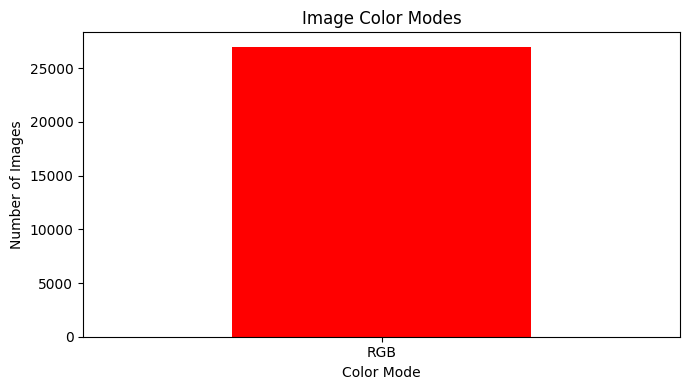

format
PNG    27000
Name: count, dtype: int64


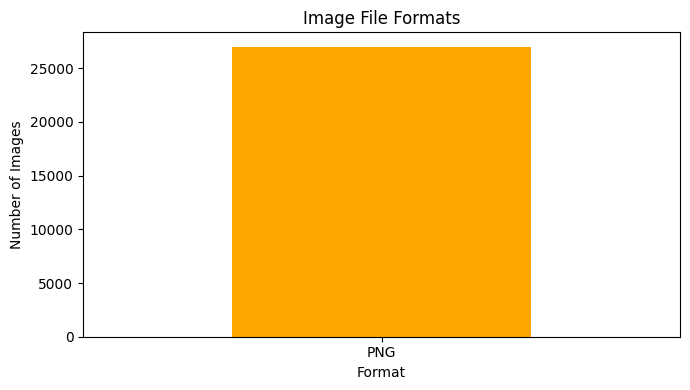

In [11]:
mode_counts = df_images["mode"].value_counts()
print(mode_counts)
plt.figure(figsize=(7, 4))
mode_counts.plot(
    kind="bar",
    color="red")

plt.title("Image Color Modes")
plt.xlabel("Color Mode")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


format_counts = df_images["format"].value_counts()
print(format_counts)
plt.figure(figsize=(7, 4))
format_counts.plot(
    kind="bar",
    color="orange"
)
plt.title("Image File Formats")
plt.xlabel("Format")
plt.ylabel("Number of Images")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

All images use RGB color mode.


All images are stored in PNG format.


## 3. Visual Exploration


### 3.1. Samples from Each Class

Display one training image per class.


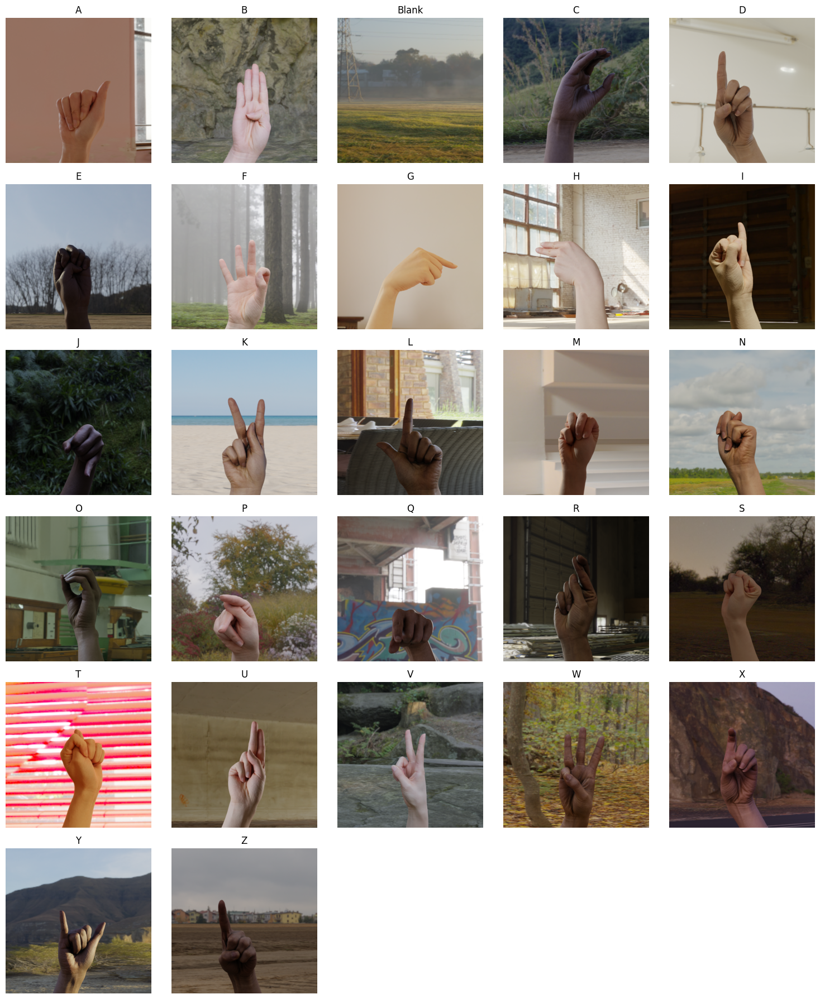

In [12]:
classes = sorted(df["Class"].unique())
cols = 5
rows = (len(classes) + cols - 1) // cols
plt.figure(figsize=(15, rows * 3))

for i in range(len(classes)):
    class_name = classes[i]

    images = df[(df["Class"] == class_name) &(df["Split"] == "train")]
    plt.subplot(rows, cols, i + 1)
    plt.title(class_name)
    plt.axis("off")
    
    if len(images) > 0:
        path = images["Path"].iloc[0]
        with Image.open(path) as img:
            plt.imshow(img.convert("RGB"))

plt.tight_layout()
plt.show()

Samples show different backgrounds and hand positions. One image per class is insufficient to assess overall diversity.


### 3.2. Within-Class Variation

Compare backgrounds, lighting, and hand positions in ten class A images.


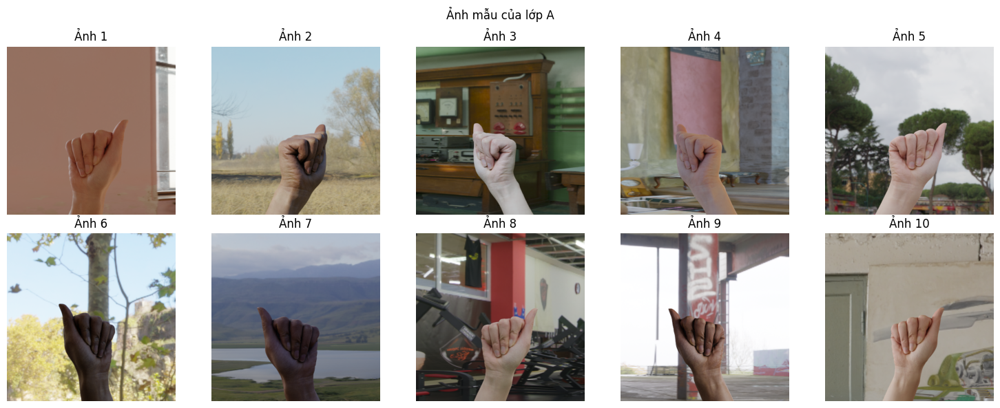

In [13]:
selected_class = "A"
images = df[
    (df["Class"] == selected_class) &
    (df["Split"] == "train")
]
paths = images["Path"].head(10).tolist()
plt.figure(figsize=(15, 6))

for i in range(len(paths)):
    plt.subplot(2, 5, i + 1)

    with Image.open(paths[i]) as img:
        plt.imshow(img.convert("RGB"))

    plt.title(f"Ảnh {i + 1}")
    plt.axis("off")

plt.suptitle(f"Ảnh mẫu của lớp {selected_class}")
plt.tight_layout()
plt.show()

Class A samples show indoor and outdoor backgrounds and different capture conditions. More samples are needed to assess diversity.


### 3.3. Between-Class Comparison

Compare hand shapes across classes A, B, C, M, N, and T.


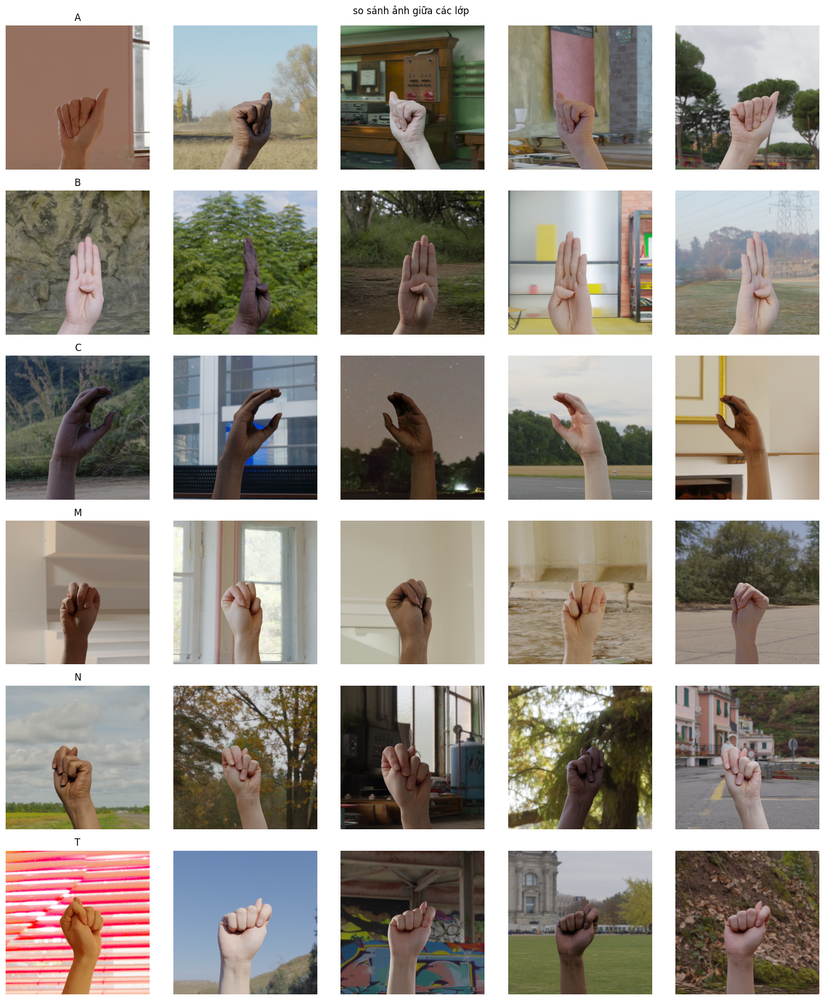

In [14]:
selected_classes = ["A", "B", "C", "M", "N", "T"]
images_per_class = 5

classes = []
for cls in selected_classes:
    if cls in df["Class"].unique():
        classes.append(cls)
if len(classes) > 0:
    plt.figure(figsize=(15, len(classes) * 3))
    for i in range(len(classes)):
        cls = classes[i]
        images = df[(df["Class"] == cls) & (df["Split"] == "train")]
        paths = images["Path"].head(images_per_class).tolist()

        for j in range(images_per_class):
            position = i * images_per_class + j + 1
            plt.subplot(len(classes), images_per_class, position)
            if j < len(paths):
                with Image.open(paths[j]) as img:
                    plt.imshow(img.convert("RGB"))
            plt.axis("off")
            if j == 0:
                plt.title(f"{cls}")

    plt.suptitle("so sánh ảnh giữa các lớp ")
    plt.tight_layout()
    plt.show()

Some signs have similar finger shapes and poses. A confusion matrix is needed to identify actual model errors.


### 3.4. Train/Test Samples

Compare samples of the same class across both splits.


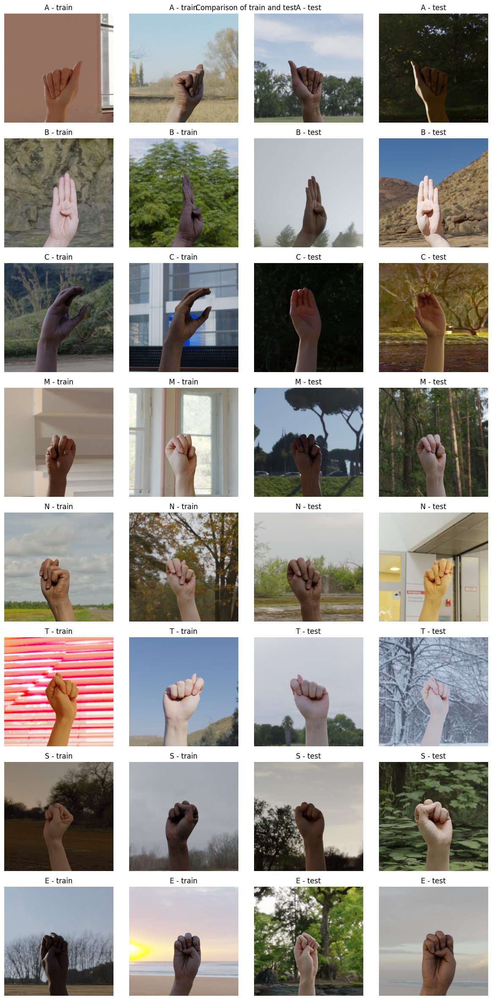

In [15]:
selected_classes = ["A", "B", "C", "M", "N", "T","S","E"]

classes = []
for cls in selected_classes:
    if cls in df["Class"].unique():
        classes.append(cls)

if len(classes) > 0:
    plt.figure(figsize=(12, len(classes) * 3))
    for i in range(len(classes)):
        cls = classes[i]
        for split in ["train", "test"]:
            images = df[(df["Class"] == cls) & (df["Split"] == split)]

            paths = images["Path"].head(2).tolist()
            if split == "train":
                start_col = 0
            else:
                start_col = 2

            for j in range(2):
                position = i * 4 + start_col + j + 1
                plt.subplot(len(classes), 4, position)

                if j < len(paths):
                    with Image.open(paths[j]) as img:
                        plt.imshow(img.convert("RGB"))
                plt.title(f"{cls} - {split}")
                plt.axis("off")

    plt.suptitle("Comparison of train and test")
    plt.tight_layout()
    plt.show()

Samples in both splits show varied backgrounds and hand positions.


## 4. Brightness, Contrast, and RGB


### 4.1. Brightness and Contrast Measures

Resize grayscale images to 128 × 128; calculate mean intensity and pixel intensity standard deviation.


In [16]:

bright_vals = []
contrast_vals = []

for fp in df["Path"]:
    with Image.open(fp) as im:
        im = im.convert("L").resize((128, 128))
        arr = np.array(im, dtype=np.float32)
        
        bright_vals.append(arr.mean())
        contrast_vals.append(arr.std())

df["Brightness"] = bright_vals
df["Contrast"] = contrast_vals
df[["Class", "Split", "Brightness", "Contrast"]].head()


,Class,Split,Brightness,Contrast
0,A,train,124.133667,29.812656
1,A,train,165.002014,41.250362
2,A,train,77.545837,39.734715
3,A,train,118.528748,26.403803
4,A,train,138.202515,69.186935


Both measures are added to the metadata table. Contrast measures intensity variation across the entire image, including the background.


### 4.2. Brightness Distribution

Plot the histogram and summarize mean image intensity.


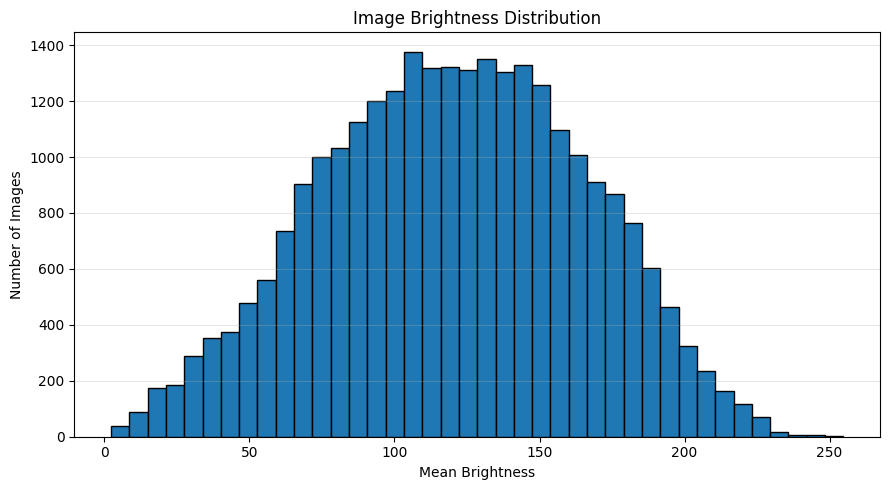

count    27000.000000
mean       120.158722
std         45.092854
min          2.278748
25%         87.353409
50%        120.936188
75%        153.281860
max        254.752869
Name: Brightness, dtype: float64


In [17]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Brightness"],
    bins=40,
    edgecolor="black"
)

plt.title("Image Brightness Distribution")
plt.xlabel("Mean Brightness")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(df["Brightness"].describe())

Mean brightness is approximately 120.16/255 (SD: 45.09), indicating substantial variation in image lighting.


### 4.3. Contrast Distribution


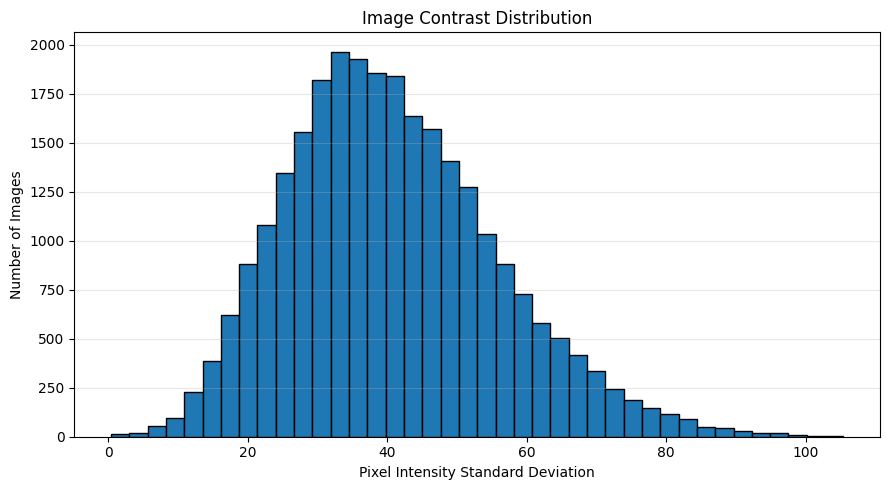

count    27000.000000
mean        40.815727
std         15.150059
min          0.432192
25%         30.004547
50%         39.336220
75%         50.203629
max        105.407867
Name: Contrast, dtype: float64


In [18]:
plt.figure(figsize=(9, 5))

plt.hist(
    df["Contrast"],
    bins=40,
    edgecolor="black"
)

plt.title("Image Contrast Distribution")
plt.xlabel("Pixel Intensity Standard Deviation")
plt.ylabel("Number of Images")
plt.grid(axis="y", alpha=0.3)

plt.tight_layout()
plt.show()

print(df["Contrast"].describe())

Mean contrast is approximately 40.82, ranging from 0.43 to 105.41. Low-contrast images require visual inspection.


### 4.4. Train/Test Brightness and Contrast

Compare brightness histograms and summary statistics across splits.


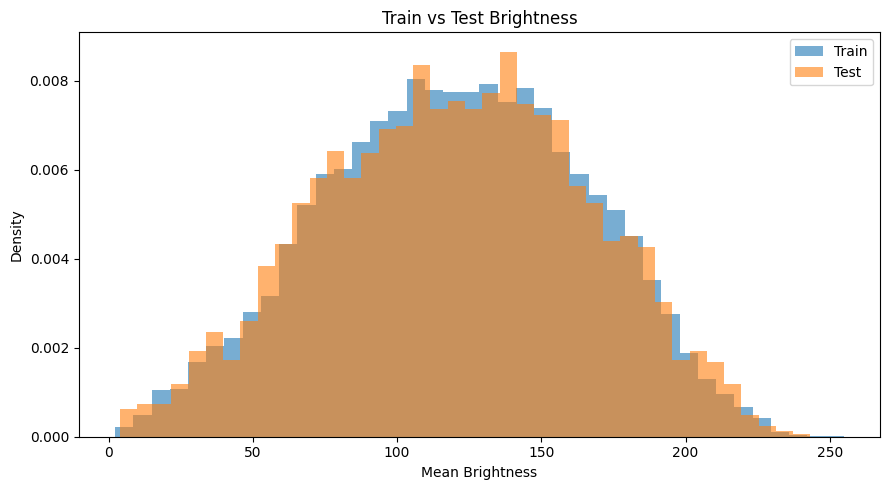

Brightness                                Contrast               \
             mean        std   min         max       mean    std   min   
Split                                                                    
test   119.879997  45.869999  3.79  243.270004  41.029999  15.17  2.36   
train  120.190002  45.009998  2.28  254.750000  40.790001  15.15  0.43   

                   
              max  
Split              
test   100.059998  
train  105.410004

In [19]:
train_brightness = df[df["Split"] == "train"]["Brightness"]
test_brightness = df[df["Split"] == "test"]["Brightness"]

plt.figure(figsize=(9, 5))

plt.hist(
    train_brightness,
    bins=40,
    alpha=0.6,
    density=True,
    label="Train"
)

plt.hist(
    test_brightness,
    bins=40,
    alpha=0.6,
    density=True,
    label="Test"
)

plt.title("Train vs Test Brightness")
plt.xlabel("Mean Brightness")
plt.ylabel("Density")
plt.legend()

plt.tight_layout()
plt.show()

display(
    df.groupby("Split")[["Brightness", "Contrast"]]
    .agg(["mean", "std", "min", "max"])
    .round(2)
)

Mean brightness is 120.19 for train and 119.80 for test; mean contrast is 40.79 and 41.03, respectively. The splits are similar on these measures.


### 4.5. RGB Distributions

Sample up to 300 images to plot the three color-channel distributions.


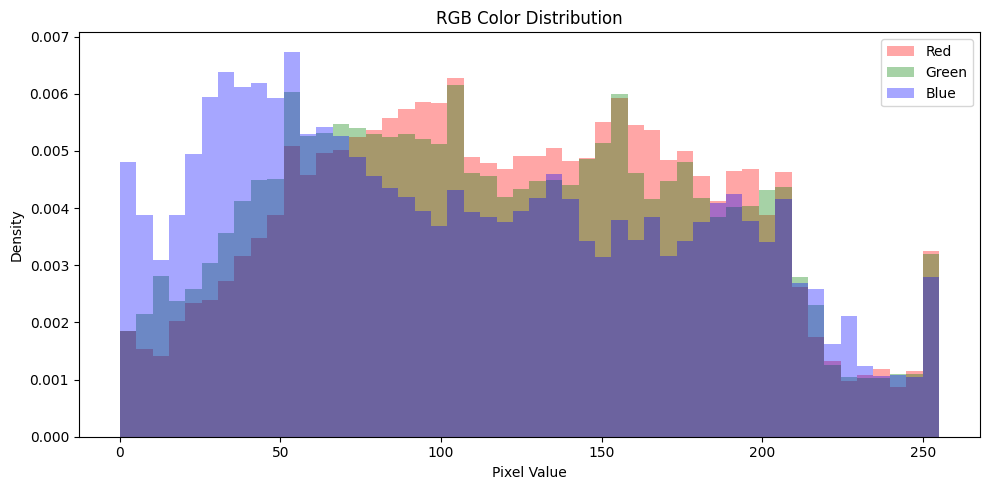

In [20]:
paths = df["Path"].sample(n=min(300, len(df)), random_state=42)
red = []
green = []
blue = []

for path in paths:
    with Image.open(path) as img:
        img = img.convert("RGB")
        img = img.resize((64, 64))
        for r, g, b in img.getdata():
            red.append(r)
            green.append(g)
            blue.append(b)

plt.figure(figsize=(10, 5))
plt.hist(red, bins=50, range=(0, 255), density=True,
         color="red", alpha=0.35, label="Red")
plt.hist(green, bins=50, range=(0, 255), density=True,
         color="green", alpha=0.35, label="Green")
plt.hist(blue, bins=50, range=(0, 255), density=True,
         color="blue", alpha=0.35, label="Blue")

plt.title("RGB Color Distribution")
plt.xlabel("Pixel Value")
plt.ylabel("Density")
plt.legend()
plt.tight_layout()
plt.show()

All three RGB channels have broad distributions influenced by background colors.


## 5. Exact Duplicate Check


### 5.1. MD5 File Hashes


In [21]:
import hashlib
hashes = []
for path in df["Path"]:
    md5 = hashlib.md5()
    with open(path, "rb") as file:
        chunk = file.read(1024 * 1024)
        while chunk:
            md5.update(chunk)
            chunk = file.read(1024 * 1024)
    hashes.append(md5.hexdigest())

df["MD5"] = hashes
print(" total :", len(df))
print("Different MD5 numbers :", df["MD5"].nunique())
print("Number of duplicate files:", df["MD5"].duplicated().sum())

 total : 27000
Different MD5 numbers : 27000
Number of duplicate files: 0


All 27,000 files have unique MD5 hashes; no byte-identical duplicates were found. Visually similar images may still exist.


## 6. EDA Conclusion

- **Dataset:** 27,000 images across 27 balanced classes, with 900 training and 100 test images per class.
- **Image properties:** All images are 513 × 512 pixels, RGB, and PNG; all file metadata was readable.
- **Variation:** Samples show different backgrounds, lighting, and hand positions. Train/test brightness and contrast are similar.
- **Duplicates:** No byte-identical files were found; visual duplicates were not assessed.
